# Transplanting base-model plan states into Qwen3-8B: demo notebook

**Question.** Qwen3-8B (instruct, thinking off) writes the same algorithm for almost every coding task. It uses
a full sort for the k-th smallest element, a sort-by-count for top-k frequent and Dijkstra for weighted shortest
paths. Its base model, Qwen3-8B-Base, is often more varied on the **identical token ids**. Is that lost variety
still recoverable at the *plan site*?

**Intervention: a cross-model state transplant.** During the instruct model's prompt prefill, the
task-specification states at decoder blocks 12-23 are *set* to

$$h[l,p] \leftarrow h_{instr}[l,p] + \lambda\,\big(h_{base}[l,p] - h_{instr}[l,p]\big), \qquad \lambda \in \{0.25, 0.5, 1\}.$$

Sampling then uses exactly the same random numbers as the unhooked *twin*: one uniform stream per
(task, template, slot), shared by every arm, so T(0) reproduces the twin token for token. **Claim B**
(pre-registered) passes on a task only if both of the following hold:
- The transplant T(λ\*) writes more correct off-default programs than three controls on the same slots, after
  Holm correction. The controls are **MR** (a norm-matched random direction), **XT** (another task's mean
  base-minus-instruct direction, norm-matched) and, where MR breaks the model, **MRP** (pass-matched random).
- It lands on the base model's own runner-up algorithm r_t.

**Frozen-rule verdict of the full artifact: Claim B DISCONFIRMED (PASS on 1 of 5 decisive tasks, T14).**

**What runs here (CPU, well under a minute).** The full pipeline needs two 8B models on a GPU with
at least 20 GiB and a 6.5 GB activation cache. This notebook re-runs its CPU half with the original code,
copied verbatim apart from a few marked notebook fixes:

| § | original source | what it does here |
|---|---|---|
| 1 | `method.py` | the stage runner (shown; launches only in a full checkout with a GPU) |
| 2 | `src/cfg.py` | constants |
| 3 | `src/analysis_b.py` | the frozen statistics and decision rules, written to disk and hash-checked against COMMIT #0 |
| 4-5 | `src/hooks5.py`, `src/gpu5.py`, `tests/test_cpu.py` | the T / MR / XT / DS edits and the hook-math and statistics unit tests, on toy tensors |
| 6-8 | `src/analysis_final.py` | the Stage-4 confirmation and the Claim B rule on the curated slots |
| 9-10 | `audit/rederive.py` | a comparison with the pipeline's numbers, and the arm-shuffle placebo |
| 11-12 | `src/figures5.py` | one slot's programs, a summary table, label compositions and a forest plot |

**Data.** `mini_demo_data.json` is **one dataset** of the artifact's `method_out.json`,
`transplant_confirmation`. It is restricted to the two decisive tasks with the clearest outcomes: **T14** (top-k
frequent), the one PASS, and **T03** (k-th smallest), where matched-norm random noise beats the transplant. Each
task contributes its 50 fresh Stage-4 slots, which makes 100 examples. Every example holds each arm's
`label|pass` on the slot and the program that arm wrote. With the default config the notebook reproduces the
pipeline's numbers for these tasks exactly (§9).

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT on Colab, always install (the original analysis modules import it)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib, pandas, torch -- pre-installed on Colab, install locally only (Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'pandas==2.2.2')
    _pip('torch==2.9.0+cpu', '--extra-index-url', 'https://download.pytorch.org/whl/cpu')

In [2]:
from __future__ import annotations

# original import blocks (method.py, src/analysis_final.py, src/analysis_b.py, src/hooks5.py, src/cfg.py,
# tests/test_cpu.py, audit/rederive.py)
import argparse
import hashlib
import json
import math
import subprocess
import sys
import time
from collections import Counter
from pathlib import Path
from typing import Any, Callable, Iterable

import numpy as np
import torch
from loguru import logger
from scipy import stats
from scipy import stats as sps

# notebook additions: importing the modules this notebook writes, plots and tables
import importlib
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-5/experiment-24/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
examples = data["datasets"][0]["examples"]
print(data["datasets"][0]["dataset"], "-", len(examples), "examples:", data["metadata"]["slots"])
print("tasks:", Counter(e["metadata_task"] for e in examples))
print("fields of one example:", sorted(examples[0]))

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
transplant_confirmation - 100 examples: S2 confirmation slots j = 10-19 x templates W1-W5 = 50 common-random-number slots per task
tasks: Counter({'T03': 50, 'T14': 50})
fields of one example: ['input', 'metadata_code_MR1_0', 'metadata_code_T1_0', 'metadata_code_TWIN', 'metadata_code_XT1_0', 'metadata_crn_key', 'metadata_model', 'metadata_slot', 'metadata_task', 'metadata_template', 'output', 'predict_MR1_0', 'predict_T1_0', 'predict_XT1_0']


## Configuration

Every tunable parameter is set here. The defaults are the original values, so the notebook reproduces the
pipeline exactly; each comment gives the original setting. Everything runs in seconds, so no value is scaled
down.

In [5]:
# ---- data: which decisive tasks, how many confirmation slots ------------------------------------------------
TASKS = ["T03", "T14"]       # tasks of mini_demo_data.json: T03 and T14 (original Stage 4: 5 decisive + 7 descriptive)
N_SLOTS_PER_TEMPLATE = 10    # S2 slots j = 10 .. 9 + N per template, x 5 templates (original 10 -> N = 50 per arm)
COMPLETE_HOLM_FAMILY = True  # decisive tasks NOT in TASKS enter the Holm family with their committed p-values
                             # (original family: 11 tests over the 5 decisive tasks; False = Holm over TASKS only)
# ---- statistics ----------------------------------------------------------------------------------------------
DEPTH = 25                   # rarefied Hill-1 depth (original 25)
N_RAREFY = 1000              # rarefaction subsamples per cell (original 1000)
N_PLACEBO_SHUFFLES = 200     # arm-shuffle placebo: within-slot shuffles per decisive task (original 200)
# ---- CPU unit tests (tests/test_cpu.py) ------------------------------------------------------------------------
HOOK_P, HOOK_N, HOOK_D = 40, 12, 64   # toy prompt length, |S| (positions 10 .. 9 + |S|, so HOOK_P >= 10 + HOOK_N),
                                      # width (original 40, 12, 64; Qwen3-8B has width 4096)
N_MCNEMAR_SIMS = 200         # exchangeable-pair simulations of the exact McNemar test (original 200)
N_COVERAGE_SIMS = 100        # simulations of the template-cluster bootstrap coverage (original 100)
N_BOOT_SIM = 300             # bootstrap replicates per coverage simulation (original 300)
# ---- the full GPU pipeline (method.py) -------------------------------------------------------------------------
PIPELINE_STAGE = None        # None = do not launch. "0".."5", "8" or "all" re-run method.py stages; that needs the
                             # full artifact checkout, both virtual envs, a >= 20 GiB GPU and the two Qwen3-8B models

## 1. The pipeline: `method.py`

`method.py` is the artifact's entry point. It is a resumable stage runner: each stage shells out to scripts in
`src/` and skips rows and files that already exist. The GPU stages hold one 8B model at a time. A label worker,
`labels5.py --follow`, runs beside stages 1-5. It labels every program with its algorithm and whether it passed
the hidden tests, using the runtime tracer first, then the AST, and a blind LLM judge only when the two
disagree.

| stage | scripts | what | wall time here |
|---|---|---|---|
| 0 | `prompts5.py`, `s0.py`, `tests/test_cpu.py` | 2,100 prompts; provenance hashes, labeller re-check, extraction test; CPU tests | about 4 min |
| 1 | `base_vllm.py` (vLLM) | base repertoire: Qwen3-8B-Base on the identical prompts | 16 min |
| 2 | `gpu5.py instr1`, `commits5.py 0` | engine check, instruct twin, clean prefill states; COMMIT #0 | 8 min |
| 3 | `audit5.py base`, `commits5.py 1` | judge audit of base labels; COMMIT #1 (default_t, β_t, r_t, strata) | 1 min |
| 4 | `gpu5.py base1` | base states; reverse interchange (instruct states into the base model) | about 35 min |
| 5 | `gpu5.py instr2` | Stage 3 selection (S1), Claim D push, COMMIT #2 (λ\*), Stage 4 confirmation (S2) | 58 min |
| 8 | `analysis_final.py`, `geometry5.py`, `audit5.py novelty`, `figures5.py`, `outputs5.py`, `audit/rederive.py` | analyses, geometry, novelty audit, figures, outputs, re-derivation | about 9 min |

The cell below is the original code with two notebook fixes. `ROOT` is the current folder (it was the script's
own folder), and the stage comes from `PIPELINE_STAGE` (it was the `--stage` argument). With the default
`PIPELINE_STAGE = None` nothing is launched. Sections 3-12 re-run the stage-8 statistics on the curated slots
instead.

In [6]:
# ---- method.py (minimal notebook fixes are marked 'notebook:') ----
ROOT = Path.cwd()  # notebook: was Path(__file__).resolve().parent
PY = str(ROOT / ".venv" / "bin" / "python")
PYV = str(ROOT / ".venv_vllm" / "bin" / "python")
SRC = ROOT / "src"


def run(cmd: list[str]) -> None:
    print(f"$ {' '.join(cmd)}", flush=True)
    t0 = time.time()
    subprocess.run(cmd, cwd=SRC, check=True)
    print(f"  done in {time.time() - t0:.0f}s", flush=True)


def start_labeller() -> subprocess.Popen:
    return subprocess.Popen([PY, "labels5.py", "--follow"], cwd=SRC,
                            stdout=open(ROOT / "logs" / "labels5.out", "a"), stderr=subprocess.STDOUT)


def main(stage: str = "all") -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--stage", default="all", choices=["0", "1", "2", "3", "4", "5", "8", "all"])
    a = ap.parse_args(["--stage", stage])  # notebook: was ap.parse_args() (command line)
    st = a.stage
    lab = None
    if st in ("1", "2", "3", "4", "5", "all"):
        lab = start_labeller()
    try:
        if st in ("0", "all"):
            run([PY, "prompts5.py"])
            run([PY, "s0.py"])
            run([PY, str(ROOT / "tests" / "test_cpu.py")])
        if st in ("1", "all"):
            run([PYV, "base_vllm.py", "--stage", "all"])
        if st in ("2", "all"):
            run([PY, "gpu5.py", "instr1"])
            run([PY, "commits5.py", "0"])
        if st in ("3", "all"):
            run([PY, "audit5.py", "base"])
            run([PY, "commits5.py", "1"])
        if st in ("4", "all"):
            run([PY, "gpu5.py", "base1", "--wait-min", "5"])
        if st in ("5", "all"):
            run([PY, "gpu5.py", "instr2", "--wait-min", "40"])
        if st in ("8", "all"):
            (ROOT / "data" / "labels_stop.flag").write_text("stop")
            run([PY, "analysis_final.py"])
            run([PY, "geometry5.py", "all"])
            run([PY, "audit5.py", "novelty"])
            run([PY, "analysis_final.py"])
            run([PY, "figures5.py"])
            run([PY, "outputs5.py"])
            run([PY, str(ROOT / "audit" / "rederive.py")])
    finally:
        if lab is not None and st != "all":
            lab.terminate()


# notebook: was `sys.exit(main())`; launches only when PIPELINE_STAGE is set
if PIPELINE_STAGE is not None:
    main(PIPELINE_STAGE)
else:
    print("PIPELINE_STAGE = None: the GPU pipeline is not launched; sections 3-12 re-run its statistics "
          "on mini_demo_data.json")

PIPELINE_STAGE = None: the GPU pipeline is not launched; sections 3-12 re-run its statistics on mini_demo_data.json


## 2. Constants: an excerpt of `src/cfg.py`

These are the design constants the copied functions use, verbatim. The hooked band is blocks 12-23. The
selection slots S1 are j = 0-9 and the fresh confirmation slots S2 are j = 10-19. One helper is replaced:
`catalogue(task)` read each task's catalogue of known algorithms from the bench `spec.json`. Here it reads the
copy stored in `mini_demo_data.json`.

In [7]:
# ---- src/cfg.py (excerpt, verbatim) ----
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"
BASE_ID = "Qwen/Qwen3-8B-Base"
BASE_REVISION = "49e3418fbbbca6ecbdf9608b4d22e5a407081db4"   # ITER1 exp5 reproducibility.md (pinned for comparability)
N_LAYERS = 36
D_MODEL = 4096
TEMPLATE_IDS = ["W1", "W2", "W3", "W4", "W5"]
V_BLOCKS = list(range(12, 24))          # transplant / push band (task-spec positions, prefill only)
EARLY_BLOCKS = list(range(0, 12))
LATE_BLOCKS = list(range(24, 36))
S1_SLOTS = list(range(10))              # selection slots j = 0..9 (N = 50 per task)
S2_SLOTS_100 = list(range(10, 30))      # confirmation slots (N = 100)
S2_SLOTS_50 = list(range(10, 20))       # confirmation slots (N = 50)
LAMBDAS = (0.25, 0.5, 1.0)
BETA_DIVERSE = 0.20
BETA_COLLAPSED = 0.05
DEFAULT_SHARE_MIN = 0.6
PASS_FRAC = 0.8


def stable_seed(*parts: Any) -> int:
    """Deterministic 63-bit seed from arbitrary parts (sha256 of their '|'-joined repr) -- exp8/exp17 convention."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


# notebook: replaces cfg.catalogue(), which read inputs/exp11/bench/<task>/spec.json
def catalogue(task: str) -> list[str]:
    return list(data["metadata"]["catalogue"][task])


for t in TASKS:
    print(t, "catalogue:", catalogue(t))

T03 catalogue: ['full_sort', 'size_k_heap', 'heapify_pop', 'quickselect', 'median_of_medians', 'counting_sort']
T14 catalogue: ['sort_by_count', 'heap', 'bucket_sort', 'quickselect_counts']


## 3. The frozen statistics: `src/analysis_b.py`

This module was hash-committed in COMMIT #0, before any sample it governs was drawn. The next cell writes it to
disk byte for byte. The cell after imports it as `A`, exactly as `analysis_final.py` does, and checks its
sha256 against the commit. The key definitions:

- **correct**: the program passed every hidden test and a program was extracted.
- **y(slot)**: 1 if the program on that common-random-number slot is correct **and** uses a catalogue algorithm
  other than the instruct default `default_t`. This is the McNemar outcome.
- **off-default share**: among correct programs, the share that uses a non-default catalogue algorithm.
  Non-catalogue labels ('other') stay in the denominator.
- **One-sided exact McNemar** on the discordant pairs: b = #(arm 1, control 0), c = #(arm 0, control 1),
  p = P(Binomial(b + c, 1/2) ≥ b). **Holm** correction runs over the family of decisive tasks.
- **Claim B rule per task:**
  - (i) pass(T) ≥ 0.8 × pass(twin);
  - (ii) off-share(T) ≥ β_t / 2, where β_t is the base model's off-default share;
  - (iii) T beats MR and XT, plus MRP if MR broke the model, at Holm p < 0.05;
  - (iv) T's modal off-default algorithm is the base runner-up r_t.
- **Verdict:**
  - CONFIRMED if at least ⌈2·n_div/3⌉ decisive tasks PASS and specificity holds;
  - DISCONFIRMED if every decisive task keeps its pass rate and (iii) fails on more than a third of them;
  - PARTIAL otherwise.

In [8]:
%%writefile analysis_b.py
#!/usr/bin/env python3
"""Frozen analysis code (sha256 committed in COMMIT #0): statistics and the pre-registered decision rules for
Claim B (transplant reopens the base repertoire), Claim D (de-sharpening push) and the reverse interchange.

Definitions (also restated in predictions/commit0.json):
- correct(r)       := passed every hidden test AND a program was extracted (label != 'invalid').
- catalogue label  := a label in the task's catalogue; 'other' and 'invalid' are never catalogue labels.
- off-default share (among correct) := n(correct, catalogue label != default_t) / n(correct); 'other' stays in the
                      denominator only.
- y(slot)          := 1[correct AND catalogue label != default_t] (per CRN slot; the McNemar outcome).
- default_t        := modal correct label of the S1 twin if its share among correct >= 0.6, else None.
- beta_t           := off-default share of the BASE_CHAT programs w.r.t. default_t (fewer than 20 correct even after
                      the top-up -> the same share over parseable attempts, flagged ATTEMPT).
- r_t              := the most frequent correct non-default catalogue label of BASE_CHAT (ties: more attempts, then
                      alphabetical).
- strata           := BASE-DIVERSE beta >= 0.20; BASE-COLLAPSED beta < 0.05; INTERMEDIATE otherwise.
Tests: one-sided exact McNemar = binomial(b, b + c, 1/2) upper tail on the discordant pairs of y; Holm over the
decisive family; Wilson intervals for shares, Newcombe (hybrid score) intervals for differences.
"""

from __future__ import annotations

import math
from collections import Counter
from typing import Any, Iterable

import numpy as np
from scipy import stats as sps

NON_CATALOGUE = {"other", "invalid", None, "unknown", "unresolved", "no_code"}


# ------------------------------------------------------------------------------------------------ row helpers
def is_correct(r: dict[str, Any]) -> bool:
    return bool(r.get("passed")) and r.get("label") not in ("invalid", None)


def is_valid(r: dict[str, Any]) -> bool:
    return r.get("label") not in ("invalid", None)


def cat_label(r: dict[str, Any], cat: Iterable[str]) -> str | None:
    lab = r.get("label")
    return lab if lab in set(cat) else None


def y_off(r: dict[str, Any], default: str | None, cat: Iterable[str]) -> int:
    lab = cat_label(r, cat)
    return int(is_correct(r) and lab is not None and default is not None and lab != default)


def z_def(r: dict[str, Any], default: str | None) -> int:
    return int(is_correct(r) and default is not None and r.get("label") == default)


def composition(rows: list[dict[str, Any]], correct_only: bool = True) -> dict[str, int]:
    c = Counter(r.get("label") for r in rows if (is_correct(r) if correct_only else is_valid(r)))
    return dict(sorted(c.items(), key=lambda kv: (-kv[1], str(kv[0]))))


def off_share(rows: list[dict[str, Any]], default: str | None, cat: Iterable[str],
              attempts: bool = False) -> tuple[float | None, int, int]:
    """(share, k, n): among correct programs (attempts=True: among parseable attempts)."""
    pool = [r for r in rows if (is_valid(r) if attempts else is_correct(r))]
    cs = set(cat)
    k = sum(1 for r in pool if r.get("label") in cs and r.get("label") != default)
    return (k / len(pool) if pool else None), k, len(pool)


def default_share(rows: list[dict[str, Any]], default: str | None, attempts: bool = False
                  ) -> tuple[float | None, int, int]:
    pool = [r for r in rows if (is_valid(r) if attempts else is_correct(r))]
    k = sum(1 for r in pool if r.get("label") == default)
    return (k / len(pool) if pool else None), k, len(pool)


def pass_rate(rows: list[dict[str, Any]]) -> tuple[float | None, int, int]:
    n = len(rows)
    k = sum(is_correct(r) for r in rows)
    return (k / n if n else None), k, n


# ------------------------------------------------------------------------------------------------ diversity
def hill1(counts: dict[str, int] | Counter) -> float | None:
    v = np.array([c for c in counts.values() if c > 0], dtype=float)
    if v.sum() == 0:
        return None
    p = v / v.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


def rarefied_hill1(labels: list[str], depth: int = 25, n_sub: int = 1000, seed: int = 20261021
                   ) -> dict[str, Any]:
    """Mean Hill-1 over n_sub subsamples of `depth` correct programs without replacement (fewer: all, flagged)."""
    n = len(labels)
    if n == 0:
        return {"hill1": None, "n": 0, "flag_below_depth": True}
    if n <= depth:
        return {"hill1": hill1(Counter(labels)), "n": n, "flag_below_depth": n < depth}
    rng = np.random.default_rng(seed)
    arr = np.array(labels, dtype=object)
    vals = []
    for _ in range(n_sub):
        sub = arr[rng.choice(n, size=depth, replace=False)]
        vals.append(hill1(Counter(sub.tolist())))
    return {"hill1": float(np.mean(vals)), "n": n, "flag_below_depth": False}


# ------------------------------------------------------------------------------------------------ intervals
def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float | None, float | None]:
    if n == 0:
        return None, None
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return max(0.0, c - h), min(1.0, c + h)


def newcombe(k1: int, n1: int, k2: int, n2: int) -> dict[str, float | None]:
    """Newcombe (1998) method 10 hybrid score interval for p1 - p2 (independent proportions)."""
    if n1 == 0 or n2 == 0:
        return {"diff": None, "lo": None, "hi": None}
    p1, p2 = k1 / n1, k2 / n2
    l1, u1 = wilson(k1, n1)
    l2, u2 = wilson(k2, n2)
    d = p1 - p2
    lo = d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2)
    hi = d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)
    return {"diff": d, "lo": lo, "hi": hi}


# ------------------------------------------------------------------------------------------------ tests
def mcnemar_exact(a: list[int], b: list[int]) -> dict[str, Any]:
    """Paired binary outcomes (same CRN slots): H1 one-sided a > b. b_ = #(a=1, b=0), c_ = #(a=0, b=1)."""
    assert len(a) == len(b)
    b_ = sum(1 for x, y in zip(a, b) if x == 1 and y == 0)
    c_ = sum(1 for x, y in zip(a, b) if x == 0 and y == 1)
    n = b_ + c_
    if n == 0:
        return {"b": 0, "c": 0, "n_pairs": len(a), "p_one": 1.0, "p_two": 1.0}
    p_one = float(sps.binom.sf(b_ - 1, n, 0.5))
    p_two = float(min(1.0, 2 * min(sps.binom.cdf(b_, n, 0.5), sps.binom.sf(b_ - 1, n, 0.5))))
    return {"b": b_, "c": c_, "n_pairs": len(a), "p_one": p_one, "p_two": p_two}


def binom_upper(k: int, n: int, p0: float) -> float:
    if n == 0:
        return 1.0
    return float(sps.binom.sf(k - 1, n, min(max(p0, 1e-12), 1 - 1e-12)))


def holm(pvals: dict[str, float]) -> dict[str, float]:
    keys = sorted(pvals, key=lambda k: pvals[k])
    m = len(keys)
    out: dict[str, float] = {}
    run = 0.0
    for i, k in enumerate(keys):
        adj = min(1.0, (m - i) * pvals[k])
        run = max(run, adj)
        out[k] = run
    return out


def pair_rows(a_rows: list[dict[str, Any]], b_rows: list[dict[str, Any]]) -> list[tuple[dict, dict]]:
    """Pair rows of two arms on the same (template, slot)."""
    bm = {(r["template"], int(r["slot"])): r for r in b_rows}
    out = []
    for r in a_rows:
        k = (r["template"], int(r["slot"]))
        if k in bm:
            out.append((r, bm[k]))
    return sorted(out, key=lambda p: (p[0]["template"], int(p[0]["slot"])))


def template_robustness(a_rows: list[dict[str, Any]], b_rows: list[dict[str, Any]], default: str | None,
                        cat: Iterable[str]) -> dict[str, Any]:
    cat = list(cat)
    out = {}
    n_gt = 0
    for w in sorted({r["template"] for r in a_rows}):
        ya = [y_off(r, default, cat) for r in a_rows if r["template"] == w]
        yb = [y_off(r, default, cat) for r in b_rows if r["template"] == w]
        ra = float(np.mean(ya)) if ya else None
        rb = float(np.mean(yb)) if yb else None
        out[w] = {"y_rate_arm": ra, "y_rate_control": rb}
        n_gt += int(ra is not None and rb is not None and ra > rb)
    return {"by_template": out, "n_templates_arm_gt_control": n_gt, "n_templates": len(out)}


# ------------------------------------------------------------------------------------------------ base repertoire
def default_from_twin(rows: list[dict[str, Any]], min_share: float = 0.6) -> tuple[str | None, float | None]:
    comp = composition(rows)
    n = sum(comp.values())
    if n == 0:
        return None, None
    lab, k = max(comp.items(), key=lambda kv: (kv[1], str(kv[0]) == "other" and -1 or 0, str(kv[0])))
    share = k / n
    if lab in NON_CATALOGUE or share < min_share:
        return None, share
    return lab, share


def runner_up(rows: list[dict[str, Any]], default: str | None, cat: Iterable[str]) -> str | None:
    cs = set(cat)
    corr = Counter(r["label"] for r in rows if is_correct(r) and r.get("label") in cs and r["label"] != default)
    if not corr:
        return None
    att = Counter(r["label"] for r in rows if is_valid(r) and r.get("label") in cs)
    return sorted(corr, key=lambda m: (-corr[m], -att.get(m, 0), m))[0]


def stratum(beta: float | None, diverse: float = 0.20, collapsed: float = 0.05) -> str | None:
    if beta is None:
        return None
    if beta >= diverse:
        return "BASE-DIVERSE"
    if beta < collapsed:
        return "BASE-COLLAPSED"
    return "INTERMEDIATE"


def base_beta(rows: list[dict[str, Any]], default: str | None, cat: Iterable[str], min_correct: int = 20
              ) -> dict[str, Any]:
    s, k, n = off_share(rows, default, cat)
    flag = n < min_correct
    if flag:
        s2, k2, n2 = off_share(rows, default, cat, attempts=True)
        return {"beta": s2, "k": k2, "n": n2, "basis": "ATTEMPT", "n_correct": n, "beta_correct_only": s}
    return {"beta": s, "k": k, "n": n, "basis": "CORRECT", "n_correct": n}


def beta_bootstrap(rows: list[dict[str, Any]], default: str | None, cat: Iterable[str], B: int = 2000,
                   seed: int = 20261021, min_correct: int = 20) -> dict[str, Any]:
    """Template-cluster bootstrap: resample the 5 templates with replacement (all rows of a template together)."""
    by_w: dict[str, list[dict[str, Any]]] = {}
    for r in rows:
        by_w.setdefault(r["template"], []).append(r)
    ws = sorted(by_w)
    rng = np.random.default_rng(seed)
    point = base_beta(rows, default, cat, min_correct)
    st0 = stratum(point["beta"])
    vals, same = [], 0
    for _ in range(B):
        pick = rng.choice(len(ws), size=len(ws), replace=True)
        rr = [r for i in pick for r in by_w[ws[i]]]
        b = base_beta(rr, default, cat, min_correct)["beta"]
        if b is None:
            continue
        vals.append(b)
        same += int(stratum(b) == st0)
    if not vals:
        return {"ci": [None, None], "stability": None, "n_boot": 0}
    return {"ci": [float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))],
            "stability": same / len(vals), "n_boot": len(vals)}


def smoothed_landing(rows: list[dict[str, Any]], default: str | None, cat: Iterable[str]) -> dict[str, float]:
    modes = [m for m in cat if m != default]
    c = Counter(r["label"] for r in rows if is_correct(r) and r.get("label") in set(modes))
    tot = sum(c.values()) + 0.5 * len(modes)
    return {m: (c.get(m, 0) + 0.5) / tot for m in modes} if modes else {}


def derangement(tasks: list[str], seed: int) -> dict[str, str]:
    """Seeded random derangement (no fixed points) by rejection sampling of permutations."""
    rng = np.random.default_rng(seed)
    ts = sorted(tasks)
    if len(ts) < 2:
        return {}
    while True:
        perm = rng.permutation(len(ts))
        if all(perm[i] != i for i in range(len(ts))):
            return {ts[i]: ts[int(perm[i])] for i in range(len(ts))}


# ------------------------------------------------------------------------------------------------ rules
def select_lambda(cells: dict[float, dict[str, Any]], twin_pass: float, frac: float = 0.8) -> float | None:
    """cells[lam] = {'pass': p, 'off_share': s}; lam* = argmax off_share among lam with pass >= frac * twin_pass;
    ties -> the smaller lambda; none -> None (UNTESTED)."""
    ok = [(lam, c) for lam, c in cells.items() if c.get("pass") is not None and c["pass"] >= frac * twin_pass
          and c.get("off_share") is not None]
    if not ok:
        return None
    best = max(c["off_share"] for _, c in ok)
    return min(lam for lam, c in ok if c["off_share"] == best)


def broken(pass_arm: float | None, twin_pass: float, frac: float = 0.8) -> bool:
    return pass_arm is None or pass_arm < frac * twin_pass


def claim_b_task(*, beta: float, r_t: str | None, pass_T: float, pass_twin: float, offshare_T: float | None,
                 p_holm: dict[str, float], mr_broke: bool, modal_T: str | None) -> dict[str, Any]:
    c1 = pass_T >= 0.8 * pass_twin
    c2 = offshare_T is not None and offshare_T >= 0.5 * beta
    need = ["MR", "XT"] + (["MRp"] if mr_broke else [])
    c3 = all(p_holm.get(k, 1.0) < 0.05 for k in need)
    c3_mr = p_holm.get("MR", 1.0) < 0.05 and (not mr_broke or p_holm.get("MRp", 1.0) < 0.05)
    c3_xt = p_holm.get("XT", 1.0) < 0.05
    c4 = modal_T is not None and modal_T == r_t
    return {"i_pass": c1, "ii_share": c2, "iii_controls": c3, "iii_vs_MR": c3_mr, "iii_vs_XT": c3_xt,
            "iv_landing": c4, "PASS": bool(c1 and c2 and c3 and c4), "controls_required": need}


def claim_b_verdict(task_res: dict[str, dict[str, Any]], n_div: int, specificity: bool, valid: bool
                    ) -> dict[str, Any]:
    if not valid:
        return {"verdict": "UNTESTED", "reason": "validity gate failed"}
    if n_div < 3:
        return {"verdict": "DESCRIPTIVE", "reason": f"only {n_div} BASE-DIVERSE tasks with a default (< 3)"}
    dec = {t: r for t, r in task_res.items() if r.get("decisive")}
    n_pass = sum(1 for r in dec.values() if r["rule"]["PASS"])
    need = math.ceil(2 * n_div / 3)
    n_iii_fail = sum(1 for r in dec.values() if not r["rule"]["iii_controls"])
    pass_ok = all(r["rule"]["i_pass"] for r in dec.values())
    if n_pass >= need and specificity:
        v = "CONFIRMED"
    elif pass_ok and n_iii_fail > len(dec) / 3:
        v = "DISCONFIRMED"
    else:
        v = "PARTIAL"
    branches = []
    if v == "PARTIAL":
        if any(r["rule"]["iii_vs_MR"] and not r["rule"]["iii_vs_XT"] for r in dec.values()):
            branches.append("beats MR but not XT -> a generic base shift reopens")
        if not specificity:
            branches.append("specificity failed (READ moves or collapsed tasks move)")
        if any(r["rule"]["iii_controls"] and not r["rule"]["iv_landing"] for r in dec.values()):
            branches.append("lands off r_t -> reopens, but not the base runner-up")
    return {"verdict": v, "n_decisive": len(dec), "n_pass": n_pass, "needed": need, "n_iii_fail": n_iii_fail,
            "specificity": specificity, "branches": branches}


def escapes(*, k_off: int, n: int, off_share_arm: float | None, off_share_twin: float, pass_arm: float,
            pass_twin: float, twin_k: int, twin_n: int) -> dict[str, Any]:
    """Claim D cell rule: off-default share (among correct) >= twin + 0.20 AND pass >= 0.8 x twin AND one-sided exact
    binomial p < 0.05 of k_off (correct off-default slots out of n) against the twin's smoothed per-slot rate
    p0 = (twin_k + 0.5) / (twin_n + 1)."""
    p0 = (twin_k + 0.5) / (twin_n + 1)
    p = binom_upper(k_off, n, p0)
    ok = (off_share_arm is not None and off_share_arm >= off_share_twin + 0.20 and pass_arm >= 0.8 * pass_twin
          and p < 0.05)
    return {"escapes": bool(ok), "p_binom": p, "p0": p0}


def claim_d_task(a_ds: float | None, a_iso: float | None, ds_landing: str | None, r_t: str | None) -> dict[str, Any]:
    if a_ds is None:
        return {"PASS": False, "reason": "DS never escapes"}
    if a_iso is None:  # ISO censored above 2
        ok = a_ds <= 1.0
    else:
        ok = a_ds <= 0.5 * a_iso
    return {"PASS": bool(ok and ds_landing == r_t), "dose_ok": bool(ok), "landing_ok": ds_landing == r_t}


def claim_d_verdict(task_res: dict[str, dict[str, Any]]) -> dict[str, Any]:
    if not task_res:
        return {"verdict": "UNTESTED"}
    n = len(task_res)
    n_pass = sum(1 for r in task_res.values() if r["rule"]["PASS"])
    better = sum(1 for r in task_res.values()
                 if r["a_ds"] is not None and (r["a_iso"] is None or r["a_ds"] < r["a_iso"]))
    if n_pass >= math.ceil(2 * n / 3):
        v = "CONFIRMED"
    elif better == 0:
        v = "DISCONFIRMED"
    else:
        v = "PARTIAL"
    return {"verdict": v, "n_tasks": n, "n_pass": n_pass, "n_ds_earlier_than_iso": better}


def reverse_prediction(share_rt: float | None, share_btwin: float | None, share_instr_twin: float | None
                       ) -> dict[str, Any]:
    if None in (share_rt, share_btwin, share_instr_twin):
        return {"met": None}
    need = share_btwin + 0.5 * (share_instr_twin - share_btwin)
    return {"met": bool(share_rt >= need), "threshold": need, "rise": share_rt - share_btwin,
            "predicted_min_rise": 0.5 * (share_instr_twin - share_btwin)}


def jsd(p: dict[str, int], q: dict[str, int]) -> float:
    keys = sorted(set(p) | set(q), key=str)
    a = np.array([p.get(k, 0) for k in keys], float)
    b = np.array([q.get(k, 0) for k in keys], float)
    if a.sum() == 0 or b.sum() == 0:
        return float("nan")
    a, b = a / a.sum(), b / b.sum()
    m = (a + b) / 2

    def kl(x, y):
        nz = x > 0
        return float((x[nz] * np.log2(x[nz] / y[nz])).sum())
    return 0.5 * kl(a, m) + 0.5 * kl(b, m)


def log_score(landings: list[str], dist: dict[str, float]) -> float | None:
    if not landings or not dist:
        return None
    return float(np.mean([math.log(max(dist.get(l, 0.0), 1e-12)) for l in landings]))

Overwriting analysis_b.py


In [9]:
sys.path.insert(0, str(Path.cwd()))  # notebook: was str(Path(__file__).resolve().parent), as in src/analysis_final.py
importlib.invalidate_caches()        # notebook: the module file was just written; refresh the import caches
import analysis_b as A   # the frozen module, imported as src/analysis_final.py imports it

h = hashlib.sha256(Path("analysis_b.py").read_bytes()).hexdigest()
print("analysis_b.py sha256", h[:16], "... identical to the COMMIT #0 frozen code:",
      h == data["metadata"]["frozen_code_sha256"]["analysis_b.py"])

analysis_b.py sha256 2d8ab2ac3283cf5b ... identical to the COMMIT #0 frozen code: True


## 4. The interventions: `src/hooks5.py`

Every edit is applied **in the prompt prefill only**, at the outputs of the hooked decoder blocks, on the
task-specification positions S. The math is fp32, cast back to bf16. `h_ref` is the recipient's own clean state
and `D = h_donor - h_recipient`, that is, base minus instruct for the forward transplant.

- **T(λ)**: `h <- h_ref + λ·D`. At λ = 1 this is exactly the base state. The state is **set**, not added to, so
  nothing compounds across blocks 12-23.
- **MR(λ)**: `h <- h_ref + λ·‖D‖·u`. One isotropic unit `u` per sample, norm-matched per (block, position), in
  a random direction.
- **XT(λ)**: `h <- h_ref + λ·‖D‖·unit(D̄_partner)`. The mean base-minus-instruct direction of *another* task
  (seeded derangement), norm-matched.
- **DS(α) / ISO(α)** (Claim D): a displacement-targeted push along unit(D), or along a random unit.

`gpu5.Ctx.make_edits` builds the per-block targets with these lines. They need the cached Qwen3 states, so they
are shown here, not run:
```python
if sp["kind"] == "SET" or sp["kind"] == "TS":
    targets[l] = href + sp["lam"] * D
elif sp["kind"] in ("MR", "TSMR"):
    targets[l] = href + sp["lam"] * D.norm(dim=-1, keepdim=True) * u[None]
else:  # XT
    targets[l] = href + sp["lam"] * D.norm(dim=-1, keepdim=True) * unit_rows(ub[l][None])
return edits_setto(blocks, abs_idx, targets), info
```

In [10]:
%%writefile hooks5.py
#!/usr/bin/env python3
"""Block-output edits of this artifact (all applied in the PROMPT PREFILL only, at the hooked blocks' outputs;
fp32 math, cast back to the model dtype). h_ref = the cached clean state of the RECIPIENT model for the same prompt;
D[l,p] = h_donor[l,p] - h_recipient[l,p] (base minus instruct for the forward transplant).

SETTO kinds (the hooked state is SET, so it is independent of the upstream state: nothing compounds):
  SET(lam):  h[l,p] <- h_ref[l,p] + lam * D[l,p]                               (transplant; lam = 1 -> donor state)
  MR(lam):   h[l,p] <- h_ref[l,p] + lam * ||D[l,p]|| * u_s                      (norm-matched random; one isotropic unit
                                                                                 u_s per sample, shared by all blocks
                                                                                 and positions)
  XT(lam):   h[l,p] <- h_ref[l,p] + lam * ||D_t[l,p]|| * unit(Dbar_partner[l])  (cross-task content control)
ALONG kinds (exp19 ADD/PN: displacement-targeted along a unit direction; orthogonal components left free):
  DS(alpha): h <- h + (alpha * n[l,p] - (h - h_ref) . d[l,p]) d[l,p],  d = D / ||D|| per (l,p)
  ISO(alpha): the same with one isotropic unit u_s per sample;  n[l,p] = ||h_instr[l,p]|| * r_Q(l) (ban-free unit)
  EC_RAND:   exp17 engine-check push: one fixed direction, exp17 ban unit n[l,p]
"""

from __future__ import annotations

from typing import Callable

import torch


def edits_setto(blocks: list[int], idx: torch.Tensor, targets: dict[int, torch.Tensor]
                ) -> dict[int, Callable[[torch.Tensor], torch.Tensor]]:
    """targets: {l: fp32 [len(idx), D]} -> h[:, idx] = target (batch-1 prefill)."""
    edits = {}
    for l in blocks:
        def f(h: torch.Tensor, l: int = l) -> torch.Tensor:
            h = h.clone()
            h[:, idx] = targets[l].to(h.dtype)[None]
            return h
        edits[l] = f
    return edits


def edits_along(blocks: list[int], idx: torch.Tensor, dirs: dict[int, torch.Tensor], tgt: dict[int, torch.Tensor],
                h_ref: dict[int, torch.Tensor]) -> dict[int, Callable[[torch.Tensor], torch.Tensor]]:
    """dirs: {l: fp32 [len(idx), D] unit rows or [D]}; tgt: {l: fp32 [len(idx)]}; h_ref: {l: fp32 [len(idx), D]}."""
    edits = {}
    for l in blocks:
        def f(h: torch.Tensor, l: int = l) -> torch.Tensor:
            hs = h[:, idx].float()                                  # [1, n, D]
            d = dirs[l] if dirs[l].dim() == 2 else dirs[l][None].expand(hs.shape[1], -1)
            comp = ((hs - h_ref[l][None]) * d[None]).sum(-1)        # [1, n]
            coef = tgt[l][None] - comp
            new = hs + coef[..., None] * d[None]
            h = h.clone()
            h[:, idx] = new.to(h.dtype)
            return h
        edits[l] = f
    return edits


def unit_rows(x: torch.Tensor, eps: float = 1e-8) -> torch.Tensor:
    return x / x.norm(dim=-1, keepdim=True).clamp(min=eps)

Overwriting hooks5.py


In [11]:
importlib.invalidate_caches()  # notebook: hooks5.py was just written; refresh the import caches
from hooks5 import edits_along, edits_setto, unit_rows  # as src/gpu5.py and tests/test_cpu.py import them

h = hashlib.sha256(Path("hooks5.py").read_bytes()).hexdigest()
print("hooks5.py sha256", h[:16], "... identical to the COMMIT #0 frozen code:",
      h == data["metadata"]["frozen_code_sha256"]["hooks5.py"])


# ---- src/gpu5.py: the per-sample isotropic unit of MR / ISO, verbatim ----
def iso_unit(*key: Any) -> np.ndarray:
    x = np.random.Generator(np.random.PCG64(stable_seed(*key))).standard_normal(D_MODEL)
    return (x / np.linalg.norm(x)).astype(np.float32)


# the MR(1) direction of slot T14|W1|10 is fully determined by its key (sha256 -> PCG64), as in the pipeline
u = iso_unit("iter5d2", "MR", "T14", "W1", 10, 1.0)
print("MR unit for T14|W1|10: seed", stable_seed("iter5d2", "MR", "T14", "W1", 10, 1.0),
      "| width", u.shape[0], "| norm", round(float(np.linalg.norm(u)), 6))

hooks5.py sha256 d87558c941e8774c ... identical to the COMMIT #0 frozen code: True
MR unit for T14|W1|10: seed 2746912549018221672 | width 4096 | norm 1.0


## 5. CPU unit tests: `tests/test_cpu.py`

`hook_tests` checks the edit math on random bf16 tensors:
- SET(0) is the identity, and SET(1) gives the donor exactly;
- MR's displacement has norm λ‖D‖;
- the DS push lands on its target along d;
- XT points along unit(D̄_partner).

`stats_tests` checks the statistics. The exact McNemar test on exchangeable pairs must reject at about the
nominal 5%. The template-cluster bootstrap CI of β must cover the truth in simulated data. The code is
verbatim; only the sizes come from the config.

In [12]:
# ---- tests/test_cpu.py (sizes from the config) ----
def hook_tests() -> dict:
    g = torch.Generator().manual_seed(0)
    P, n, D = HOOK_P, HOOK_N, HOOK_D  # notebook: was 40, 12, 64
    idx = torch.arange(10, 10 + n)
    h = (torch.randn(1, P, D, generator=g) * 3).to(torch.bfloat16)
    href = h[0, idx].float()
    hd = (torch.randn(n, D, generator=g) * 3).to(torch.bfloat16).float()
    Dm = hd - href
    res = {}
    e0 = edits_setto([5], idx, {5: href + 0.0 * Dm})[5](h)
    res["SET0_identity"] = bool(torch.equal(e0, h))
    e1 = edits_setto([5], idx, {5: href + 1.0 * Dm})[5](h)
    res["SET1_equals_donor"] = bool(torch.equal(e1[0, idx].float(), hd.to(torch.bfloat16).float()))
    u = torch.randn(D, generator=g)
    u = u / u.norm()
    lam = 0.5
    t_mr = href + lam * Dm.norm(dim=-1, keepdim=True) * u[None]
    disp = (t_mr - href).norm(dim=-1)
    res["MR_norm_rel_err"] = float(((disp - lam * Dm.norm(dim=-1)).abs() / (lam * Dm.norm(dim=-1))).max())
    res["MR_norm_ok"] = res["MR_norm_rel_err"] < 1e-4
    d = unit_rows(Dm)
    tgt = torch.full((n,), 2.0)
    hf = h.float()
    e2 = edits_along([5], idx, {5: d}, {5: tgt}, {5: href})[5](hf)
    along = ((e2[0, idx] - href) * d).sum(-1)
    res["DS_along_err"] = float((along - tgt).abs().max())
    res["DS_ok"] = res["DS_along_err"] < 1e-4
    dbar = torch.randn(D, generator=g)
    t_xt = href + 1.0 * Dm.norm(dim=-1, keepdim=True) * unit_rows(dbar[None])
    cosv = torch.nn.functional.cosine_similarity(t_xt - href, dbar[None].expand(n, -1), dim=-1)
    res["XT_cos_min"] = float(cosv.min())
    res["XT_ok"] = res["XT_cos_min"] > 1 - 1e-5
    res["all_pass"] = all(v for k, v in res.items() if k.endswith(("_ok", "identity", "donor")))
    return res


def stats_tests() -> dict:
    rng = np.random.default_rng(1)
    rej = 0
    for _ in range(N_MCNEMAR_SIMS):  # notebook: was 200
        p = rng.uniform(0.1, 0.5, size=50)
        a = (rng.uniform(size=50) < p).astype(int)
        b = (rng.uniform(size=50) < p).astype(int)
        rej += A.mcnemar_exact(a.tolist(), b.tolist())["p_one"] < 0.05
    cover = 0
    for s in range(N_COVERAGE_SIMS):  # notebook: was 100
        r2 = np.random.default_rng(100 + s)
        rows = []
        for w in ["W1", "W2", "W3", "W4", "W5"]:
            for j in range(10):
                lab = "x" if r2.uniform() < 0.3 else "d"
                rows.append({"template": w, "slot": j, "label": lab, "passed": True})
        ci = A.beta_bootstrap(rows, "d", ["d", "x"], B=N_BOOT_SIM, seed=s)["ci"]
        cover += ci[0] <= 0.3 <= ci[1]
    return {"mcnemar_shuffled_rejection_rate": rej / N_MCNEMAR_SIMS, "mcnemar_ok": rej / N_MCNEMAR_SIMS <= 0.08,
            "beta_ci_coverage": cover / N_COVERAGE_SIMS, "beta_ci_ok": cover / N_COVERAGE_SIMS >= 0.85,
            "note": "the template-cluster bootstrap with 5 clusters is anti-conservative; coverage is reported"}


# the script's __main__ block (it also wrote results/unit_tests.json)
out = {"hooks": hook_tests(), "stats": stats_tests()}
out["all_pass"] = bool(out["hooks"]["all_pass"] and out["stats"]["mcnemar_ok"])
unit_tests = out
print(json.dumps(unit_tests, indent=1))
print("identical to the artifact's results/unit_tests.json:",
      unit_tests == data["metadata"]["published"]["unit_tests"],
      "(expected at the default sizes; other sizes, or another torch/BLAS build, change the floats)")

{
 "hooks": {
  "SET0_identity": true,
  "SET1_equals_donor": true,
  "MR_norm_rel_err": 1.147601906836826e-07,
  "MR_norm_ok": true,
  "DS_along_err": 4.76837158203125e-07,
  "DS_ok": true,
  "XT_cos_min": 0.9999999403953552,
  "XT_ok": true,
  "all_pass": true
 },
 "stats": {
  "mcnemar_shuffled_rejection_rate": 0.025,
  "mcnemar_ok": true,
  "beta_ci_coverage": 0.86,
  "beta_ci_ok": true,
  "note": "the template-cluster bootstrap with 5 clusters is anti-conservative; coverage is reported"
 },
 "all_pass": true
}
identical to the artifact's results/unit_tests.json: True (expected at the default sizes; other sizes, or another torch/BLAS build, change the floats)


## 6. From the curated slots to label rows

`method_out.json` stores one example per common-random-number slot. `output` is the unhooked twin's
`label|pass`. Each `predict_<arm>` is a hooked arm's `label|pass` on **the same slot**: identical prompt token
ids, identical sampling uniforms, and only the prefill states at blocks 12-23 differ. The original analysis
reads one row per program (`data/labels.jsonl`), so this small adapter rebuilds those rows. It is the only new
analysis code in the notebook, and it keeps only `TASKS` and the first `N_SLOTS_PER_TEMPLATE` slots of each
template.

In [13]:
# notebook adapter: one example per slot ('label|pass' per arm) -> one row per program, as in data/labels.jsonl
def rows_from_examples(examples: list[dict[str, Any]]) -> list[dict[str, Any]]:
    rows = []
    for e in examples:
        if e["metadata_task"] not in TASKS or e["metadata_slot"] >= 10 + N_SLOTS_PER_TEMPLATE:
            continue
        cols = {"TWIN": e["output"]}
        cols.update({k[len("predict_"):]: v for k, v in e.items() if k.startswith("predict_")})
        for col, lp in cols.items():
            label, outcome = lp.rsplit("|", 1)
            rows.append({"task": e["metadata_task"], "arm": col.replace("_", "."),  # 'T1_0' -> arm 'T1.0'
                         "template": e["metadata_template"], "slot": e["metadata_slot"],
                         "model": e["metadata_model"], "label": None if label == "None" else label,
                         "passed": outcome == "pass", "code": e.get(f"metadata_code_{col}", "")})
    return rows


labs = rows_from_examples(examples)
print(len(labs), "label rows")
for (t, arm), k in sorted(Counter((r["task"], r["arm"]) for r in labs).items()):
    print(f"  {t} {arm:7s} {k} programs")

450 label rows
  T03 MR1.0   50 programs
  T03 T1.0    50 programs
  T03 TWIN    50 programs
  T03 XT1.0   50 programs
  T14 MR1.0   50 programs
  T14 MRP0.5  50 programs
  T14 T1.0    50 programs
  T14 TWIN    50 programs
  T14 XT1.0   50 programs


## 7. Per-arm cells: `sel()` and `cell()` from `src/analysis_final.py`

`cell()` summarises one arm on one task:
- the pass rate, with a Wilson CI;
- the correct off-default share and the y-rate;
- the label compositions;
- rarefied Hill-1 diversity at depth 25;
- the modal correct non-default algorithm.

The code is verbatim, except that the number of rarefaction subsamples comes from `N_RAREFY`.

In [14]:
# ---- src/analysis_final.py: sel, cell ----
def sel(labs: list[dict[str, Any]], task: str, arm: str, slots: set[int] | list[int] | None = None,
        model: str | None = None) -> list[dict[str, Any]]:
    s = set(slots) if slots is not None else None
    return [r for r in labs if r["task"] == task and r["arm"] == arm and (s is None or int(r["slot"]) in s)
            and (model is None or r.get("model") == model)]


def cell(rows: list[dict[str, Any]], d: str | None, cat: list[str]) -> dict[str, Any]:
    n = len(rows)
    pr, kp, _ = A.pass_rate(rows)
    sh, ko, nc = A.off_share(rows, d, cat)
    y = [A.y_off(r, d, cat) for r in rows]
    comp = A.composition(rows)
    corr = [r["label"] for r in rows if A.is_correct(r)]
    return {"n": n, "pass": pr, "k_pass": kp, "pass_wilson": A.wilson(kp, n), "n_correct": nc, "off_share": sh,
            "k_off": ko, "off_wilson": A.wilson(ko, nc) if nc else [None, None],
            "y_rate": float(np.mean(y)) if y else None, "k_y": int(sum(y)),
            "default_share": A.default_share(rows, d)[0],
            "composition_correct": comp, "composition_attempted": A.composition(rows, correct_only=False),
            "n_other_correct": comp.get("other", 0), "n_invalid": sum(1 for r in rows if r.get("label") == "invalid"),
            "hill1_d25": A.rarefied_hill1(corr, DEPTH, N_RAREFY)["hill1"],  # notebook: was 1000
            "modal_correct_nondefault": (Counter(l for l in corr if l in set(cat) and l != d).most_common(1)[0][0]
                                         if any(l in set(cat) and l != d for l in corr) else None)}


# the twin of T14 on the configured slots, summarised by cell()
_t = TASKS[-1]
_c = cell(sel(labs, _t, "TWIN", S2_SLOTS_50, "Qwen/Qwen3-8B"), data["metadata"]["commit1"]["per_task"][_t]["default"],
          catalogue(_t))
print(_t, "twin S2:", {k: _c[k] for k in ("n", "pass", "n_correct", "off_share", "composition_correct", "hill1_d25")})

T14 twin S2: {'n': 50, 'pass': 0.78, 'n_correct': 39, 'off_share': 0.0, 'composition_correct': {'sort_by_count': 39}, 'hill1_d25': 1.0}


## 8. Stage 4 confirmation and the Claim B rule: `confirmation()` from `src/analysis_final.py`

For each task in the committed Stage-4 plan, the transplant T(λ\*) is compared with each control on the fresh
S2 slots, using paired one-sided exact McNemar tests on y. The p-values of the decisive tasks form the Holm
family, and the frozen per-task rule and verdict follow.

The committed constants come from the data file:
- COMMIT #1: default_t, β_t, r_t and the strata;
- COMMIT #2: λ\* = 1 on both tasks. MR(1) broke T14 (pass 0.53 against 0.78), so the pass-matched MRP(0.5) is
  required there;
- the S1 specificity result.

There are two notebook changes, both marked in the code:
1. The iteration-4 push landings (`inputs/exp22/escape.json`) come from the data file.
2. With `COMPLETE_HOLM_FAMILY = True`, the decisive tasks outside the mini data (T2, T10, T1) enter the Holm
   family with their committed p-values. Holm-adjusted p then equal the pipeline's 11-test family.

In [15]:
# ---- src/analysis_final.py: confirmation ----
def confirmation(c1: dict[str, Any], c2: dict[str, Any], labs: list[dict[str, Any]], spec: dict[str, Any],
                 ext: bool = False) -> dict[str, Any]:
    """ext=True: the committed post-hoc power extension (COMMIT3_EXT, descriptive): decisive tasks on S2 j 10-29."""
    per = c1["per_task"]
    BD, INT = c1["strata"]["BASE-DIVERSE"], c1["strata"]["INTERMEDIATE"]
    res: dict[str, Any] = {}
    family: dict[str, float] = {}
    for t, cells in c2["stage4_plan"].items():
        if ext and t not in BD:
            continue
        d, cat = per[t]["default"], catalogue(t)
        n2 = 100 if ext else c2["s2_N"].get(t, 50)
        slots = S2_SLOTS_100 if n2 == 100 else S2_SLOTS_50
        tw = sel(labs, t, "TWIN", slots, "Qwen/Qwen3-8B")
        arms = [a for a, _ in cells if a != "TWIN"]
        T_arm = arms[0]
        r = {"decisive": t in BD, "N": n2, "lambda_star": c2["selection"][t]["lambda_star"],
             "twin_S2": cell(tw, d, cat), "arms": {}}
        Trows = sel(labs, t, T_arm, slots)
        for a in arms:
            rows = sel(labs, t, a, slots)
            c = cell(rows, d, cat)
            if a != T_arm and rows and Trows:
                pairs = A.pair_rows(Trows, rows)
                c["mcnemar_T_vs_this"] = A.mcnemar_exact([A.y_off(x, d, cat) for x, _ in pairs],
                                                         [A.y_off(y, d, cat) for _, y in pairs])
                c["template_robustness"] = A.template_robustness(Trows, rows, d, cat)
                c["y_diff_newcombe"] = A.newcombe(sum(A.y_off(x, d, cat) for x in Trows), len(Trows),
                                                  sum(A.y_off(y, d, cat) for y in rows), len(rows))
                ctl = "MR" if a.startswith("MR") and not a.startswith("MRP") else (
                    "XT" if a.startswith("XT") else "MRp")
                c["control_class"] = ctl
                if t in BD:
                    family[f"{t}|{ctl}"] = c["mcnemar_T_vs_this"]["p_one"]
            if rows and tw:
                pairs = A.pair_rows(rows, tw)
                c["mcnemar_vs_twin_y"] = A.mcnemar_exact([A.y_off(x, d, cat) for x, _ in pairs],
                                                         [A.y_off(y, d, cat) for _, y in pairs])
            r["arms"][a] = c
        res[t] = r
    if COMPLETE_HOLM_FAMILY:  # notebook: decisive tasks outside the mini data, committed p-values
        family.update({k: v for k, v in data["metadata"]["holm_family_committed"].items()
                       if k.split("|")[0] not in res})
    holm = A.holm(family) if family else {}
    for t, r in res.items():
        r["holm"] = {k.split("|")[1]: v for k, v in holm.items() if k.startswith(t + "|")}
        if r["decisive"]:
            Tc = r["arms"][next(iter(r["arms"]))]
            mr_broke = bool(c2["selection"][t]["MR_broken_at_lambda_star"])
            r["rule"] = A.claim_b_task(beta=per[t]["beta"], r_t=per[t]["r_t"], pass_T=Tc["pass"] or 0.0,
                                       pass_twin=r["twin_S2"]["pass"] or 0.0, offshare_T=Tc["off_share"],
                                       p_holm=r["holm"], mr_broke=mr_broke,
                                       modal_T=Tc["modal_correct_nondefault"])
            if mr_broke and "MRp" not in r["holm"]:  # lambda' = None -> ISO(1) comparator
                r["rule"]["note"] = "MR broke and no unbroken MR: ISO(1) used as the pass-matched comparator"
    valid = bool(c2["validity_gate"]["valid"])
    verdict = A.claim_b_verdict(res, c1["n_div"], spec["holds"], valid)
    # sensitivities
    sens = {}
    stab = [t for t in BD if (per[t]["stratum_stability"] or 0) >= 0.8]
    sub = {t: res[t] for t in stab if t in res}
    sens["stable_stratum_only"] = A.claim_b_verdict(sub, len(stab), spec["holds"], valid)
    sens["noise_robust_specificity"] = A.claim_b_verdict(res, c1["n_div"], spec["holds_noise_robust"], valid)
    plain_div = [t for t in c1["tasks_with_default"] if per[t]["base_plain"]["stratum_plain"] == "BASE-DIVERSE"]
    sens["plain_completion_strata"] = {"BASE-DIVERSE_plain": plain_div,
                                       "tested_in_stage4": [t for t in plain_div if t in res],
                                       "n_pass_among_tested": sum(1 for t in plain_div if t in res and
                                                                  res[t].get("rule", {}).get("PASS"))}
    sens["excluding_low_confidence"] = [t for t in BD if per[t]["low_confidence"]]
    tr = {}
    for t, r in res.items():
        tr[t] = {a: c.get("template_robustness", {}).get("n_templates_arm_gt_control")
                 for a, c in r["arms"].items() if "template_robustness" in c}
    sens["template_robustness_counts"] = tr
    sens["attempt_basis_tasks"] = [t for t in BD if per[t]["beta_basis"] == "ATTEMPT"]
    # descriptive: log score of the committed landing composition vs uniform and vs the exp22 push landing
    esc = data["metadata"]["exp22_escape"]  # notebook: was read_json(E22 / "escape.json")
    ls = {}
    for t, r in res.items():
        Tc = r["arms"][next(iter(r["arms"]))]
        d, cat = per[t]["default"], catalogue(t)
        land = [l for l, k in Tc["composition_correct"].items() for _ in range(k) if l in set(cat) and l != d]
        pred = per[t]["predicted_landing_composition"]
        uni = {m: 1 / max(len(pred), 1) for m in pred}
        push = esc.get(t, {}).get("push_landing_v4") or {}
        ls[t] = {"n_landings": len(land), "log_score_base_pred": A.log_score(land, pred),
                 "log_score_uniform": A.log_score(land, uni),
                 "log_score_push_landing": A.log_score([l for l in land if l in push], push) if push else None,
                 "n_landings_defined_under_push": sum(1 for l in land if l in push)}
    return {"per_task": res, "holm_family": family, "holm_adjusted": holm, "verdict": verdict,
            "sensitivities": sens, "landing_log_scores": ls}

In [16]:
c1 = data["metadata"]["commit1"]        # COMMIT #1: per-task default_t, beta_t, r_t, strata (n_div = 5)
c2 = dict(data["metadata"]["commit2"])  # COMMIT #2: lambda*, MR breakage, the Stage-4 plan
c2["stage4_plan"] = {t: v for t, v in c2["stage4_plan"].items() if t in TASKS}
s = {"specificity": data["metadata"]["specificity"]}   # results/selection.json (S1)

# as in analysis_final.main()
cf = confirmation(c1, c2, labs, s["specificity"])
claim_b = {"verdict": cf["verdict"], "sensitivities": cf["sensitivities"], "specificity": s["specificity"],
           "validity_gate": c2["validity_gate"],
           "per_task_rule": {t: r.get("rule") for t, r in cf["per_task"].items()},
           "holm_adjusted": cf["holm_adjusted"]}


# ---- src/report5.py: f, pval, verbatim ----
def f(x: Any, nd: int = 2) -> str:
    if x is None:
        return "–"
    if isinstance(x, bool):
        return "yes" if x else "no"
    if isinstance(x, float):
        return f"{x:.{nd}f}"
    return str(x)


def pval(p: Any) -> str:
    if p is None:
        return "–"
    return f"{p:.2g}" if p >= 1e-3 else f"{p:.1e}"


# report lines as written by src/report5.py
for t, r in cf["per_task"].items():
    ru = r["rule"]
    T = next(iter(r["arms"]))
    print(f"- {t} (lambda* {r['lambda_star']}, T = {T}): (i) pass {f(ru['i_pass'])}, (ii) share >= 0.5 beta "
          f"{f(ru['ii_share'])}, (iii) controls {f(ru['iii_controls'])}, (iv) lands on r_t {f(ru['iv_landing'])} "
          f"-> PASS {f(ru['PASS'])}   [controls required: {', '.join(ru['controls_required'])}]")
v = cf["verdict"]
print(f"\nverdict over TASKS = {TASKS}: {v['verdict']} (PASS {v.get('n_pass')}/{v.get('n_decisive')}, "
      f"needed {v.get('needed')} of n_div = {c1['n_div']}; (iii) fails on {v.get('n_iii_fail')})")
pv = data["metadata"]["published"]["verdict"]
print(f"committed verdict over all 5 decisive tasks: {pv['verdict']} (PASS {pv['n_pass']}/{pv['n_decisive']}, "
      f"needed {pv['needed']}; (iii) fails on {pv['n_iii_fail']})")
print("Holm-adjusted p (family of", len(cf["holm_family"]), "tests):",
      {k: float(f"{p:.3g}") for k, p in cf["holm_adjusted"].items() if k.split("|")[0] in TASKS})


- T03 (lambda* 1.0, T = T1.0): (i) pass yes, (ii) share >= 0.5 beta no, (iii) controls no, (iv) lands on r_t no -> PASS no   [controls required: MR, XT]
- T14 (lambda* 1.0, T = T1.0): (i) pass yes, (ii) share >= 0.5 beta yes, (iii) controls yes, (iv) lands on r_t yes -> PASS yes   [controls required: MR, XT, MRp]

verdict over TASKS = ['T03', 'T14']: DISCONFIRMED (PASS 1/2, needed 4 of n_div = 5; (iii) fails on 1)
committed verdict over all 5 decisive tasks: DISCONFIRMED (PASS 1/5, needed 4; (iii) fails on 4)
Holm-adjusted p (family of 11 tests): {'T14|MRp': 5.25e-06, 'T14|MR': 1.91e-05, 'T14|XT': 0.000652, 'T03|XT': 1.0, 'T03|MR': 1.0}


The frozen verdict function is applied to the tasks in `TASKS`, while `n_div = 5` and the "needed" count come
from COMMIT #1. With T03 and T14 it already returns **DISCONFIRMED**: T14 passes, but (iii) fails on T03, which
is more than a third of the decisive tasks present. The committed verdict over all five decisive tasks is
printed beside it.

## 9. Does the notebook reproduce the pipeline?

Each number above is compared with the value the pipeline wrote to `results/confirmation.json`, stored in the
data file under `published`. At the default config, with all 10 slots per template, every row matches. With
fewer slots, mismatches are expected.

In [17]:
pub = data["metadata"]["published"]["per_task"]
close = lambda a, b: (a is None and b is None) or (a is not None and b is not None and abs(a - b) <= 1e-12 * max(1.0, abs(b)))
cmp_rows, rule_match = [], {}
for t, r in cf["per_task"].items():
    P = pub[t]
    for a in ["twin_S2"] + list(r["arms"]):
        mine = r["twin_S2"] if a == "twin_S2" else r["arms"][a]
        theirs = P["twin_S2"] if a == "twin_S2" else P["arms"][a]
        mm, mt = mine.get("mcnemar_T_vs_this") or {}, theirs.get("mcnemar_T_vs_this") or {}
        ctl = mine.get("control_class")
        row = {"task": t, "arm": a, "pass": mine["pass"], "k_off": mine["k_off"], "n_correct": mine["n_correct"],
               "McNemar b:c": f"{mm['b']}:{mm['c']}" if mm else "",
               "Holm p": r["holm"].get(ctl) if ctl else None}
        row["match"] = bool(close(mine["pass"], theirs["pass"]) and mine["k_off"] == theirs["k_off"]
                            and mine["n_correct"] == theirs["n_correct"]
                            and mine["modal_correct_nondefault"] == theirs["modal_correct_nondefault"]
                            and (mm.get("b"), mm.get("c")) == (mt.get("b"), mt.get("c"))
                            and close(mm.get("p_one"), mt.get("p_one"))
                            and (not ctl or close(r["holm"].get(ctl), P["holm"].get(ctl))))
        cmp_rows.append(row)
    rule_match[t] = r["rule"] == P["rule"]
cmp = pd.DataFrame(cmp_rows)
display(cmp)
print(f"{int(cmp['match'].sum())} of {len(cmp)} rows match the pipeline's results/confirmation.json",
      "(expected: all, at N_SLOTS_PER_TEMPLATE = 10)")
print("per-task Claim B rule identical to the pipeline's:", rule_match)

,task,arm,pass,k_off,n_correct,McNemar b:c,Holm p,match
0,T03,twin_S2,1.00,0,50,,NaN,True
1,T03,T1.0,1.00,3,50,,NaN,True
2,T03,MR1.0,1.00,21,50,2:20,1.000000,True
3,T03,XT1.0,1.00,0,50,3:0,1.000000,True
4,T14,twin_S2,0.78,0,39,,NaN,True
5,T14,T1.0,0.98,21,49,,NaN,True
6,T14,MR1.0,0.78,2,39,19:0,0.000019,True
7,T14,XT1.0,0.88,5,44,17:1,0.000652,True
8,T14,MRP0.5,0.76,0,38,21:0,0.000005,True


9 of 9 rows match the pipeline's results/confirmation.json (expected: all, at N_SLOTS_PER_TEMPLATE = 10)
per-task Claim B rule identical to the pipeline's: {'T03': True, 'T14': True}


## 10. Arm-shuffle placebo: `audit/rederive.py`

If T and the control were exchangeable, swapping their outcomes at random within each slot would make the
one-sided McNemar test reject at about its nominal 5%. It would not reproduce the effect. This is the original
placebo block. It compares T with its first control (MR) for each decisive task, with `N_PLACEBO_SHUFFLES`
shuffles each. In the full artifact, with 5 decisive tasks, the rejection rate was 0.012. The helpers are
`audit/rederive.py`'s own, which re-derives every number without importing the pipeline code.

In [18]:
# ---- audit/rederive.py: helpers, verbatim ----
def correct(r) -> bool:
    return bool(r.get("passed")) and r.get("label") not in (None, "invalid")


def yoff(r, d, c) -> int:
    return int(correct(r) and r.get("label") in c and r.get("label") != d)


def mcn(a, b):
    b_ = sum(1 for x, y in zip(a, b) if x == 1 and y == 0)
    c_ = sum(1 for x, y in zip(a, b) if x == 0 and y == 1)
    return 1.0 if b_ + c_ == 0 else float(stats.binom.sf(b_ - 1, b_ + c_, 0.5))


# notebook: the script's inputs, from this notebook (it read data/samples.jsonl and results/confirmation.json)
by = {}
for r in labs:
    by.setdefault((r["task"], r["arm"]), []).append(r)
conf, cat, out = cf, catalogue, {}

# ---- audit/rederive.py: placebo (a), verbatim apart from the shuffle count ----
# placebo (a): arm shuffle within slots
rng = np.random.default_rng(5)
rej = tot = 0
for t, r in conf["per_task"].items():
    if not r["decisive"]:
        continue
    d, c = c1["per_task"][t]["default"], cat(t)
    arms = list(r["arms"])
    slots = set(range(10, 20 if r["N"] == 50 else 30))  # N counts programs: 5 templates x slots
    Tr = {(x["template"], int(x["slot"])): x for x in by.get((t, arms[0]), []) if int(x["slot"]) in slots}
    Mr = {(x["template"], int(x["slot"])): x for x in by.get((t, arms[1]), []) if int(x["slot"]) in slots}
    keys = sorted(set(Tr) & set(Mr))
    ya = np.array([yoff(Tr[k], d, c) for k in keys])
    yb = np.array([yoff(Mr[k], d, c) for k in keys])
    for _ in range(N_PLACEBO_SHUFFLES):  # notebook: was 200
        sw = rng.uniform(size=len(keys)) < 0.5
        a2, b2 = np.where(sw, yb, ya), np.where(sw, ya, yb)
        rej += mcn(a2.tolist(), b2.tolist()) < 0.05
        tot += 1
out["placebo_arm_shuffle"] = {"rejection_rate": rej / max(tot, 1), "n": tot,
                              "pass": (rej / max(tot, 1)) <= 0.10}
print("arm-shuffle placebo:", out["placebo_arm_shuffle"])

arm-shuffle placebo: {'rejection_rate': 0.025, 'n': 400, 'pass': True}


## 11. One common-random-number slot: what the transplant changes

Every arm uses the same prompt token ids and the same sampling uniforms; only the prefill states at blocks
12-23 differ. On the T14 slot below, the twin writes the instruct default (sort by count), and T(1), carrying
the base model's exact states in the hooked band, writes the base model's runner-up (`heap`).

In [19]:
e = next(e for e in examples if e["metadata_task"] == "T14" and e["output"].startswith("sort_by_count|")
         and e["predict_T1_0"].startswith("heap|"))
print("slot", e["metadata_crn_key"], "\n\nPROMPT (user turn):\n" + e["input"])
for col in ("TWIN", "T1_0", "MR1_0", "XT1_0", "MRP0_5"):
    lp = e["output"] if col == "TWIN" else e[f"predict_{col}"]
    print(f"\n---- {col.replace('_', '.'):7s} -> {lp}\n{e[f'metadata_code_{col}'].strip()}")

slot T14|W1|12 

PROMPT (user turn):
Do not use picture for this task. . .

Task: write a Python function solve(nums, k) that returns the k values that occur most often in nums, as a list in any order. The argument nums is a list of integers with 1 <= len(nums) <= 10000 and every value between -10000 and 10000 inclusive; k is an integer between 1 and the number of distinct values in nums. The inputs are chosen so that the answer is unique: the k-th and (k+1)-th highest frequencies always differ.

Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with no example usage and no explanation.

---- TWIN    -> sort_by_count|pass
from collections import Counter

def solve(nums, k):
    count = Counter(nums)
    sorted_counts = sorted(count.items(), key=lambda x: (-x[1], x[0]))
    result = [item[0] for item in sorted_counts[:k]]
    return result

---- T1.0    -> heap|pass
from collections import Counter

def solve(nums, k

In [20]:
# descriptive: how the correct 'heap' programs of T14 are written, and the pass rate of each arm's default
for arm in ("TWIN", "T1.0", "MR1.0", "XT1.0", "MRP0.5"):
    rr = [r for r in labs if r["task"] == "T14" and r["arm"] == arm]
    if not rr:
        continue
    forms = Counter("Counter(...).most_common(k)" if "most_common(" in r["code"] else
                    ("explicit heapq" if "heapq" in r["code"] else "other")
                    for r in rr if r["label"] == "heap" and r["passed"])
    sbc = [r for r in rr if r["label"] == "sort_by_count"]
    print(f"{arm:7s} pass {sum(r['passed'] for r in rr)}/{len(rr)} | sort_by_count programs passing "
          f"{sum(r['passed'] for r in sbc)}/{len(sbc)} | correct heap programs: {dict(forms) or 0}")

TWIN    pass 39/50 | sort_by_count programs passing 39/49 | correct heap programs: 0
T1.0    pass 49/50 | sort_by_count programs passing 28/29 | correct heap programs: {'Counter(...).most_common(k)': 21}
MR1.0   pass 39/50 | sort_by_count programs passing 36/42 | correct heap programs: {'Counter(...).most_common(k)': 2}
XT1.0   pass 44/50 | sort_by_count programs passing 39/44 | correct heap programs: {'Counter(...).most_common(k)': 5}
MRP0.5  pass 38/50 | sort_by_count programs passing 38/48 | correct heap programs: 0


**A caveat visible in the programs.** Every correct program labelled `heap` in this subset is the one-liner
`Counter(nums).most_common(k)`. CPython implements that call with `heapq.nlargest`, so the runtime labeller
records a heap. At the default config, the twin's sort-by-count programs fail on 10 of 50 slots, while T(1)
passes 49 of 50. The T14 effect is therefore a shift to a library call that is a heap underneath, and that call
is more often correct. This matches the follow-up the artifact itself proposes: check whether T14's success
comes from its heap solutions being more correct.

## 12. Results

First a summary table of every arm on the configured slots, then the original figure code from
`src/figures5.py`. Its `save()` is replaced by an inline display. The figures are the correct-program label
compositions per arm, and the forest plot of the per-slot y-rate difference T - control with Newcombe 95% CIs
and Holm p. A last toy panel shows the design of the controls.

In [21]:
tab = []  # formatted with src/report5.py's f() and pval()
for t, r in cf["per_task"].items():
    per = c1["per_task"][t]
    for a in ["twin_S2"] + list(r["arms"]):
        c = r["twin_S2"] if a == "twin_S2" else r["arms"][a]
        m = c.get("mcnemar_T_vs_this")
        tab.append({"task": t, "beta_t / r_t": f"{per['beta']:.2f} / {per['r_t']}",
                    "arm": "TWIN (S2)" if a == "twin_S2" else a, "N": c["n"], "pass": f(c["pass"]),
                    "correct": c["n_correct"], "off-default": c["k_off"], "off-share": f(c["off_share"]),
                    "modal off-default": f(c["modal_correct_nondefault"]),
                    "T vs this b:c": f"{m['b']}:{m['c']}" if m else "",
                    "p one-sided": pval(m["p_one"]) if m else "", "p two-sided": pval(m["p_two"]) if m else "",
                    "Holm p": pval(r["holm"].get(c.get("control_class"))) if m else ""})
display(pd.DataFrame(tab))

,task,beta_t / r_t,arm,N,pass,correct,off-default,off-share,modal off-default,T vs this b:c,p one-sided,p two-sided,Holm p
0,T03,0.43 / quickselect,TWIN (S2),50,1.00,50,0,0.00,–,,,,
1,T03,0.43 / quickselect,T1.0,50,1.00,50,3,0.06,size_k_heap,,,,
2,T03,0.43 / quickselect,MR1.0,50,1.00,50,21,0.42,quickselect,2:20,1,1.2e-04,1
3,T03,0.43 / quickselect,XT1.0,50,1.00,50,0,0.00,–,3:0,0.12,0.25,1
4,T14,0.35 / heap,TWIN (S2),50,0.78,39,0,0.00,–,,,,
5,T14,0.35 / heap,T1.0,50,0.98,49,21,0.43,heap,,,,
6,T14,0.35 / heap,MR1.0,50,0.78,39,2,0.05,heap,19:0,1.9e-06,3.8e-06,1.9e-05
7,T14,0.35 / heap,XT1.0,50,0.88,44,5,0.11,heap,17:1,7.2e-05,1.4e-04,6.5e-04
8,T14,0.35 / heap,MRP0.5,50,0.76,38,0,0.00,–,21:0,4.8e-07,9.5e-07,5.2e-06


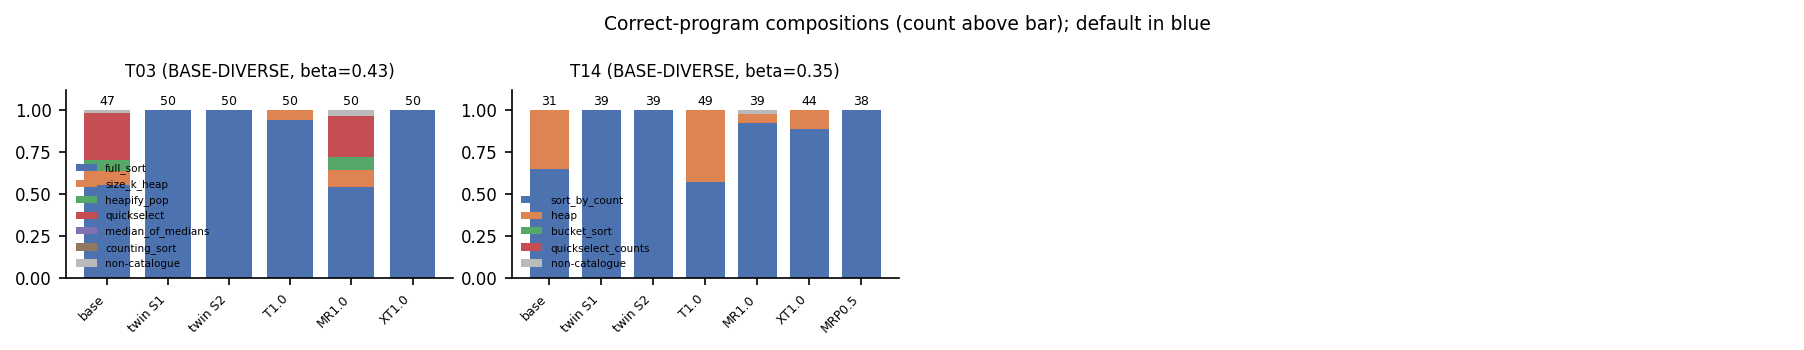

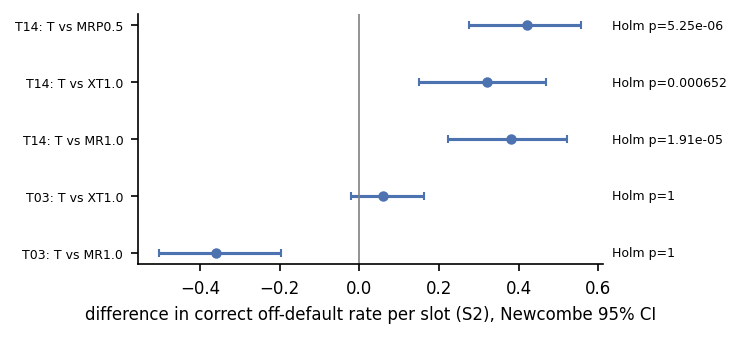

In [22]:
# ---- src/figures5.py: style, fig_compositions, fig_forest (verbatim; save() shows inline) ----
plt.rcParams.update({"font.size": 8, "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42,
                     "ps.fonttype": 42, "figure.dpi": 150})
DEF_C, OTH_C = "#4C72B0", "#BBBBBB"
PAL = ["#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860", "#DA8BC3", "#8C8C8C", "#CCB974"]


def save(fig, name: str) -> None:  # notebook: was savefig(figures/<name>.png and .pdf)
    display(fig)
    plt.close(fig)


def fig_compositions(c1, conf) -> None:
    tasks = list(conf["per_task"]) if conf else c1["strata"]["BASE-DIVERSE"]
    n = len(tasks)
    cols = 4
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.0 * cols, 2.3 * rows), squeeze=False)
    for ax, t in zip(axes.flat, tasks):
        per = c1["per_task"][t]
        d = per["default"]
        cat = catalogue(t)
        modes = [m for m in cat if m != d]
        bars = [("base", per["base_chat"]["composition_correct"]), ("twin S1", per["twin_S1"]["composition_correct"])]
        if conf and t in conf["per_task"]:
            r = conf["per_task"][t]
            bars.append(("twin S2", r["twin_S2"]["composition_correct"]))
            for a, c in r["arms"].items():
                bars.append((a, c["composition_correct"]))
        x = np.arange(len(bars))
        for i, (name, comp) in enumerate(bars):
            tot = max(sum(comp.values()), 1)
            bottom = 0.0
            seq = [(d, DEF_C)] + [(m, PAL[j % len(PAL)]) for j, m in enumerate(modes)]
            for m, colr in seq:
                v = comp.get(m, 0) / tot
                ax.bar(i, v, bottom=bottom, color=colr, width=0.75, label=m if i == 0 else None)
                bottom += v
            v = sum(k for m, k in comp.items() if m not in cat) / tot
            ax.bar(i, v, bottom=bottom, color=OTH_C, width=0.75, label="non-catalogue" if i == 0 else None)
            ax.text(i, 1.01, str(sum(comp.values())), ha="center", va="bottom", fontsize=6)
        ax.set_xticks(x)
        ax.set_xticklabels([b[0] for b in bars], rotation=45, ha="right", fontsize=6)
        ax.set_ylim(0, 1.12)
        ax.set_title(f"{t} ({per['stratum']}, beta={per['beta']:.2f})", fontsize=8)
        ax.legend(fontsize=5, frameon=False, loc="lower left", ncol=1)
    for ax in list(axes.flat)[n:]:
        ax.axis("off")
    fig.suptitle("Correct-program compositions (count above bar); default in blue", fontsize=9)
    fig.tight_layout()
    save(fig, "fig1_compositions")


def fig_forest(conf) -> None:
    rows = []
    for t, r in conf["per_task"].items():
        if not r["decisive"]:
            continue
        for a, c in r["arms"].items():
            if "y_diff_newcombe" in c:
                nd = c["y_diff_newcombe"]
                rows.append((f"{t}: T vs {a}", nd["diff"], nd["lo"], nd["hi"], r["holm"].get(c["control_class"])))
    if not rows:
        return
    fig, ax = plt.subplots(figsize=(5, 0.3 * len(rows) + 0.8))
    for i, (name, d, lo, hi, p) in enumerate(rows):
        ax.errorbar(d, i, xerr=[[d - lo], [hi - d]], fmt="o", color="#4C72B0", ms=4, capsize=2)
        ax.text(1.02, i, f"Holm p={p:.3g}" if p is not None else "", va="center", fontsize=6,
                transform=ax.get_yaxis_transform())
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([r[0] for r in rows], fontsize=6)
    ax.set_xlabel("difference in correct off-default rate per slot (S2), Newcombe 95% CI")
    fig.tight_layout()
    save(fig, "fig4_forest")


fig_compositions(c1, cf)
fig_forest(cf)

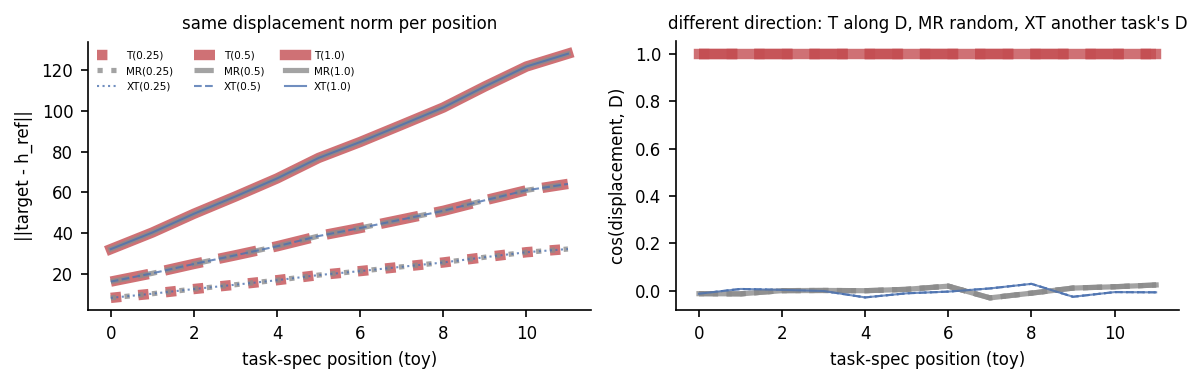

In [23]:
# Toy picture of the control design (random tensors at the real width D_MODEL, NOT model activations).
# Per position, T(lam), MR(lam) and XT(lam) move h_ref by the same norm lam*||D||; only the direction differs.
g = torch.Generator().manual_seed(0)
href = torch.randn(HOOK_N, D_MODEL, generator=g) * 3                          # stand-in recipient states at S
Dm = torch.randn(HOOK_N, D_MODEL, generator=g) * torch.linspace(0.5, 2.0, HOOK_N)[:, None]  # stand-in base - instr
u = torch.tensor(iso_unit("iter5d2", "MR", "T14", "W1", 10, 1.0))             # the seeded MR unit of one slot
dbar = torch.randn(D_MODEL, generator=g)                                       # stand-in partner-task mean direction
fig, axes = plt.subplots(1, 2, figsize=(8, 2.6))
for lam, ls in zip(LAMBDAS, (":", "--", "-")):
    arms = {"T": href + lam * Dm,                                                # gpu5.make_edits target formulas
            "MR": href + lam * Dm.norm(dim=-1, keepdim=True) * u[None],
            "XT": href + lam * Dm.norm(dim=-1, keepdim=True) * unit_rows(dbar[None])}
    for (name, tgt), col, lw in zip(arms.items(), ("#C44E52", "#8C8C8C", "#4C72B0"), (5, 2.5, 1)):  # nested widths:
        disp = tgt - href                                                                       # overlaps stay visible
        axes[0].plot(disp.norm(dim=-1), ls, color=col, lw=lw, alpha=0.8, label=f"{name}({lam})")
        axes[1].plot(torch.nn.functional.cosine_similarity(disp, Dm, dim=-1), ls, color=col, lw=lw, alpha=0.8)
axes[0].set_xlabel("task-spec position (toy)"); axes[0].set_ylabel("||target - h_ref||")
axes[0].set_title("same displacement norm per position", fontsize=8); axes[0].legend(fontsize=5, ncol=3, frameon=False)
axes[1].set_xlabel("task-spec position (toy)"); axes[1].set_ylabel("cos(displacement, D)")
axes[1].set_title("different direction: T along D, MR random, XT another task's D", fontsize=8)
for ax in axes:
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
fig.tight_layout()
display(fig)
plt.close(fig)

In [24]:
v = cf["verdict"]
print("=" * 100)
print(f"Claim B on TASKS = {TASKS}, N = {5 * N_SLOTS_PER_TEMPLATE} slots per arm: {v['verdict']}  "
      f"(committed 5-task verdict: {data['metadata']['published']['verdict']['verdict']})")
for t, r in cf["per_task"].items():
    T = next(iter(r["arms"]))
    Tc, tw = r["arms"][T], r["twin_S2"]
    ctl = ", ".join(f"{a} {c['mcnemar_T_vs_this']['b']}:{c['mcnemar_T_vs_this']['c']} "
                    f"(Holm p {r['holm'].get(c['control_class'], float('nan')):.2g})"
                    for a, c in r["arms"].items() if c.get("mcnemar_T_vs_this"))
    print(f"  {t}: twin off-default {tw['k_off']}/{tw['n_correct']} correct, pass {tw['pass']:.2f} | {T}: "
          f"{Tc['k_off']}/{Tc['n_correct']} ({Tc['modal_correct_nondefault']}), pass {Tc['pass']:.2f} | {ctl} "
          f"-> PASS {r['rule']['PASS']}")
print(f"unit tests all pass: {unit_tests['all_pass']} | arm-shuffle placebo rejection "
      f"{out['placebo_arm_shuffle']['rejection_rate']:.3f} | rows matching the pipeline: "
      f"{int(cmp['match'].sum())}/{len(cmp)}")

Claim B on TASKS = ['T03', 'T14'], N = 50 slots per arm: DISCONFIRMED  (committed 5-task verdict: DISCONFIRMED)
  T03: twin off-default 0/50 correct, pass 1.00 | T1.0: 3/50 (size_k_heap), pass 1.00 | MR1.0 2:20 (Holm p 1), XT1.0 3:0 (Holm p 1) -> PASS False
  T14: twin off-default 0/39 correct, pass 0.78 | T1.0: 21/49 (heap), pass 0.98 | MR1.0 19:0 (Holm p 1.9e-05), XT1.0 17:1 (Holm p 0.00065), MRP0.5 21:0 (Holm p 5.2e-06) -> PASS True
unit tests all pass: True | arm-shuffle placebo rejection 0.025 | rows matching the pipeline: 9/9


## What this shows

- **T14** (top-k frequent; BASE-DIVERSE, β = 0.35, r_t = heap).
  - The transplant writes the base runner-up in 21 of 49 correct programs; the twin writes it in 0 of 39.
  - It beats MR 19:0, XT 17:1 and MRP 21:0 (Holm p ≤ 7e-4), lands on r_t and passes the rule. This is the
    artifact's one large, specific effect.
  - §11 qualifies it: the heap programs are `Counter.most_common(k)`, and they are more often correct.
- **T03** (k-th smallest; β = 0.43, r_t = quickselect).
  - The transplant barely moves the default: 3 of 50 off-default, a size-k heap.
  - Matched-norm random noise moves it much more: 21 of 50, mostly quickselect (McNemar 2:20, two-sided
    p = 1.2e-4).
  - So the base-minus-instruct displacement disrupts the plan *less* than an isotropic one of the same size.
- **Frozen verdict: Claim B DISCONFIRMED** (PASS 1 of 5; (iii) fails on T03, T2, T10 and T1).
- **Not re-run here.** The full artifact also reports site controls (early blocks 0-11 move T03 and T10 more
  than the main band), Claim D (DISCONFIRMED), the reverse interchange, the plan-site geometry (MDS and Isomap
  of the cached states) and a novelty audit (0 novel algorithms among 48 non-catalogue programs). They need the
  activation cache or the other datasets.